# Notebook to generate files and SPA-C training dataset

In [1]:
import os, time, datetime

import sys
sys.path.append('../py_scripts')

# CHM13

## Splitting chromosomes in subsets

In [2]:
chm13_fa = "/home/amergez/SPA-C/datasets/raw_data/CHM13v2/CHM13v2.fa"
chm13_chrom_sizes = "/home/amergez/SPA-C/datasets/raw_data/CHM13v2/CHM13v2.fa.chrom.sizes"

In [3]:
# Getting chromosome sizes
chrom_sizes = {}
with open(chm13_chrom_sizes, "r") as handle:
    for line in handle.readlines():
        seq_name, length = line.split("\t")
        chrom_sizes[seq_name] = int(length)
chrom_sizes

# Getting the number of "intra" samples per sequence (also filtering small sequences)
samples_per_seq = {seq: (length//5000)-20 for seq, length in chrom_sizes.items() if (length//5000)-20 > 0}
samples_per_seq


{'chr1': 49657,
 'chr2': 48519,
 'chr3': 40201,
 'chr4': 38694,
 'chr5': 36389,
 'chr6': 34405,
 'chr7': 32093,
 'chr8': 29231,
 'chr9': 30103,
 'chr10': 26931,
 'chr11': 27005,
 'chr12': 26644,
 'chr13': 22693,
 'chr14': 20212,
 'chr15': 19930,
 'chr16': 19246,
 'chr17': 16835,
 'chr18': 16088,
 'chr19': 12321,
 'chr20': 13222,
 'chr21': 8998,
 'chr22': 10244,
 'chrX': 30831}

In [4]:
from sklearn.model_selection import GroupShuffleSplit
import numpy as np

seed=42
val_size = 0.1
test_size = 0.1

x, y, group = [], [], []
cur_grp = 0
for seq_name, n_samples in samples_per_seq.items():
    x.extend([seq_name]*n_samples)
    y.extend([1]*n_samples)
    group.extend([cur_grp]*n_samples)

    cur_grp += 1

x = np.array(x)
y = np.array(y)
group = np.array(group)

In [5]:
# Checking that each chromosome has a single group
for seq_name in np.unique(x):
    mask = (x == seq_name)
    print(seq_name, np.unique(group[mask]))
    

chr1 [0]
chr10 [9]
chr11 [10]
chr12 [11]
chr13 [12]
chr14 [13]
chr15 [14]
chr16 [15]
chr17 [16]
chr18 [17]
chr19 [18]
chr2 [1]
chr20 [19]
chr21 [20]
chr22 [21]
chr3 [2]
chr4 [3]
chr5 [4]
chr6 [5]
chr7 [6]
chr8 [7]
chr9 [8]
chrX [22]


In [6]:
splitter = GroupShuffleSplit(n_splits=1, test_size=val_size+test_size, random_state=seed)
train_idx, test_val_idx = next(splitter.split(
    x,
    y,
    groups=group)
)

adjusted_val_size = val_size / (val_size+test_size)

splitter_val = GroupShuffleSplit(n_splits=1, test_size=adjusted_val_size, random_state=seed)
test_idx, val_idx = next(splitter_val.split(
    x[test_val_idx],
    y[test_val_idx],
    groups=group[test_val_idx])
)

print(train_idx.shape, test_idx.shape, val_idx.shape)
print(f"Train: {np.unique(x[train_idx])}\nTest: {np.unique(x[test_val_idx][test_idx])}\nVal:{np.unique(x[test_val_idx][val_idx])}")

with open("/home/amergez/SPA-C/datasets/raw_data/CHM13v2/SPLITS.txt", "w") as handle:
    for subset, sequences in {"Train":np.unique(x[train_idx]), "Test":np.unique(x[test_val_idx][test_idx]), "Val":np.unique(x[test_val_idx][val_idx])}.items():
        handle.write(f"{subset}\t{','.join(sequences.tolist())}\n")

(468467,) (68903,) (73122,)
Train: ['chr11' 'chr12' 'chr13' 'chr14' 'chr15' 'chr17' 'chr19' 'chr2' 'chr20'
 'chr21' 'chr22' 'chr3' 'chr4' 'chr5' 'chr6' 'chr7' 'chr8' 'chrX']
Test: ['chr1' 'chr16']
Val:['chr10' 'chr18' 'chr9']


## Generating chimeras

We used ChimericContigs.py v1.6.1.

```shell
apps="apptainer" # Path to apptainer images folder
SPA_dir="SPA-C" # Directory of the Git repo
BASE_DIR="datasets"
DS="CHM13v2"
dir="${BASE_DIR}/${DS}" # Directory of CHM13 dataset

# Inter only
mkdir -p ${BASE_DIR}/${DS}.C4A/references
$apps/HiC.sif python -u ${SPA_dir}/model_training/ChimericContigs.py \
  --fasta ${dir}/references/${DS}.fa \
  --splits ${dir}/references/SPLITS.txt \
  --out ${BASE_DIR}/${DS}.C4A/references/${DS}.C4A.fa \
  --seed 42 \
  --paf ${BASE_DIR}/${DS}.C4A/references/${DS}.C4A.paf \
  --repetition 2000 \
  --size 200000 \
  --simple-names "C4A"

# Intra only
mkdir -p ${BASE_DIR}/${DS}.C4B/references
$apps/HiC.sif python -u ${SPA_dir}/model_training/ChimericContigs.py \
  --fasta ${dir}/references/${DS}.fa \
  --splits ${dir}/references/SPLITS.txt \
  --out ${BASE_DIR}/${DS}.C4B/references/${DS}.C4B.fa \
  --seed 42 \
  --paf ${BASE_DIR}/${DS}.C4B/references/${DS}.C4B.paf \
  --repetition 2500 \
  --size 200000 \
  --intra \
  --simple-names "C4B"

# Inversions only
mkdir -p ${BASE_DIR}/${DS}.C4C/references
$apps/HiC.sif python -u ${SPA_dir}/model_training/ChimericContigs.py \
  --fasta ${dir}/references/${DS}.fa \
  --splits ${dir}/references/SPLITS.txt \
  --out ${BASE_DIR}/${DS}.C4C/references/${DS}.C4C.fa \
  --seed 42 \
  --paf ${BASE_DIR}/${DS}.C4C/references/${DS}.C4C.paf \
  --repetition 2500 \
  --size 200000 \
  --inversion \
  --simple-names "C4C"
```

```shell
BASE_DIR="/home/amergez/SPA-C/datasets"

for dir in CHM13v2.C4A CHM13v2.C4B CHM13v2.C4C; do
  # Creating the dataset
  $apps/HiC.sif python -u ${SPA_dir}/py_scripts/Cool2IntraM_FullMat.py \
    --cool ${BASE_DIR}/${dir}.JHE.mcool \
    --image-size 10 \
    --bin-size 5000 \
    --breakpoint ${BASE_DIR}/raw_data/CHM13.Chimera/${dir}.bkp \
    --only-negatives \
    --output ${BASE_DIR}/CHM13.DS/${dir}.IntraFM.5K10S_Q0.hdf5 \
    --name-table ${BASE_DIR}/raw_data/CHM13.Chimera/${dir}.conversion_table.txt \
    --splits ${BASE_DIR}/raw_data/CHM13v2/SPLITS.txt \
    --padding "-1"
done
```

## Inter matrices

```shell
$apps/HiC.sif python -u ${SPA_dir}/py_scripts/Cool2InterM_FullMat.py \
  --cool ${dir}/aligned/${dir}.JHE.mcool \
  --image-size 10 \
  --bin-size 5000 \
  --steps 5 \
  --threads 8 \
  --output ${dir}/SPA-C_ds/${dir}.InterFM.5K10S_Q0.hdf5 \
  --chrom-sizes ${dir}/references/${dir}.fa.chrom.sizes \
  --splits ${dir}/references/SPLITS.txt \
  --tmp-dir ${dir}/SPA-C_ds/tmp
```

In [2]:
from SPAC_Dataset import dataset

In [3]:
inter = dataset("/home/amergez/SPA-C/datasets/CHM13v2/SPA-C_ds/CHM13v2.InterFM.5K10S_Q0.hdf5")
inter.summary()

SPA-C dataset v5.8.1

Loading /home/amergez/SPA-C/datasets/CHM13v2/SPA-C_ds/CHM13v2.InterFM.5K10S_Q0.hdf5 ...
Done ! (21.178s)
Checking if labels are identical within each groups ...
Pass !

Dataset metadata :
	Cool2InterM_FullMat.creation_date: 09/11/2026-15:43:59
	Cool2InterM_FullMat.filter: None
	Cool2InterM_FullMat.version: 1.13.1b
	data.type: Inter.FullMat
	dataset: CHM13v2.JHE

'CHM13v2.JHE' dataset summary - BS:5000 IS:10
	Whole dataset :
		x - (3771360, 20, 20)
		y - (3771360,)
		names - (3771360,)
		groups - (3771360,)
		0.0% of the samples are True


In [28]:
# Checking that chromosomes in each subset are the same as in the split file
chr_per_subset = {"Test":[], "Train":[], "Val":[]}
grp_per_subset = {"Test":[], "Train":[], "Val":[]}
for i, name in enumerate(inter.N):
    info1, info2, subset = name.split("|")
    ctg1, _ = info1.split(":")
    ctg2, _ = info2.split(":")
    chr_per_subset[subset].extend([ctg1, ctg2])
    grp_per_subset[subset].append(inter.G[i])

for key in chr_per_subset.keys():
    chr_per_subset[key] = set(chr_per_subset[key])
    grp_per_subset[key] = set(grp_per_subset[key])

print(chr_per_subset)
print(grp_per_subset)

{'Test': {'chr16', 'chr1'}, 'Train': {'chr12', 'chr20', 'chr4', 'chr21', 'chr3', 'chr11', 'chr14', 'chr2', 'chr13', 'chr17', 'chr15', 'chr8', 'chr22', 'chrX', 'chr6', 'chr5', 'chr7', 'chr19'}, 'Val': {'chr10', 'chr9', 'chr18'}}
{'Test': {np.uint16(2)}, 'Train': {np.uint16(0)}, 'Val': {np.uint16(1)}}


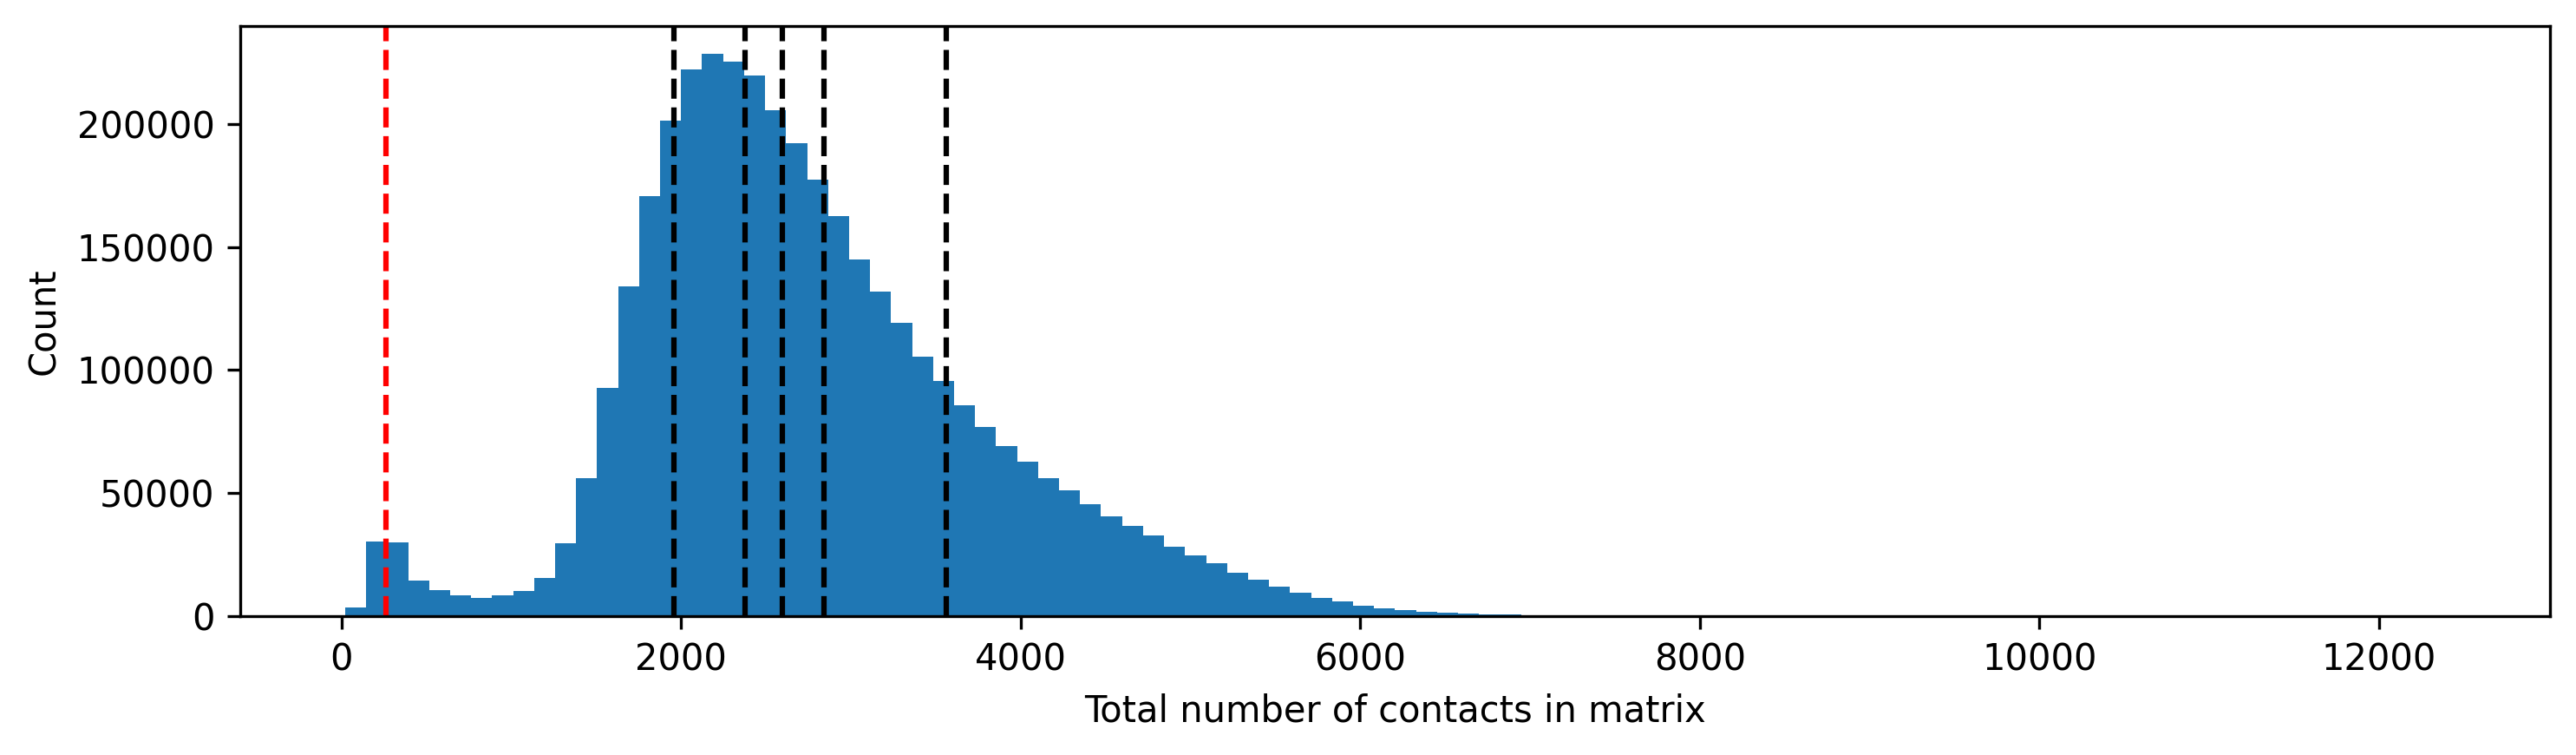

In [19]:
inter.dist()

In [20]:
inter.equalize(clip_value=1e4)

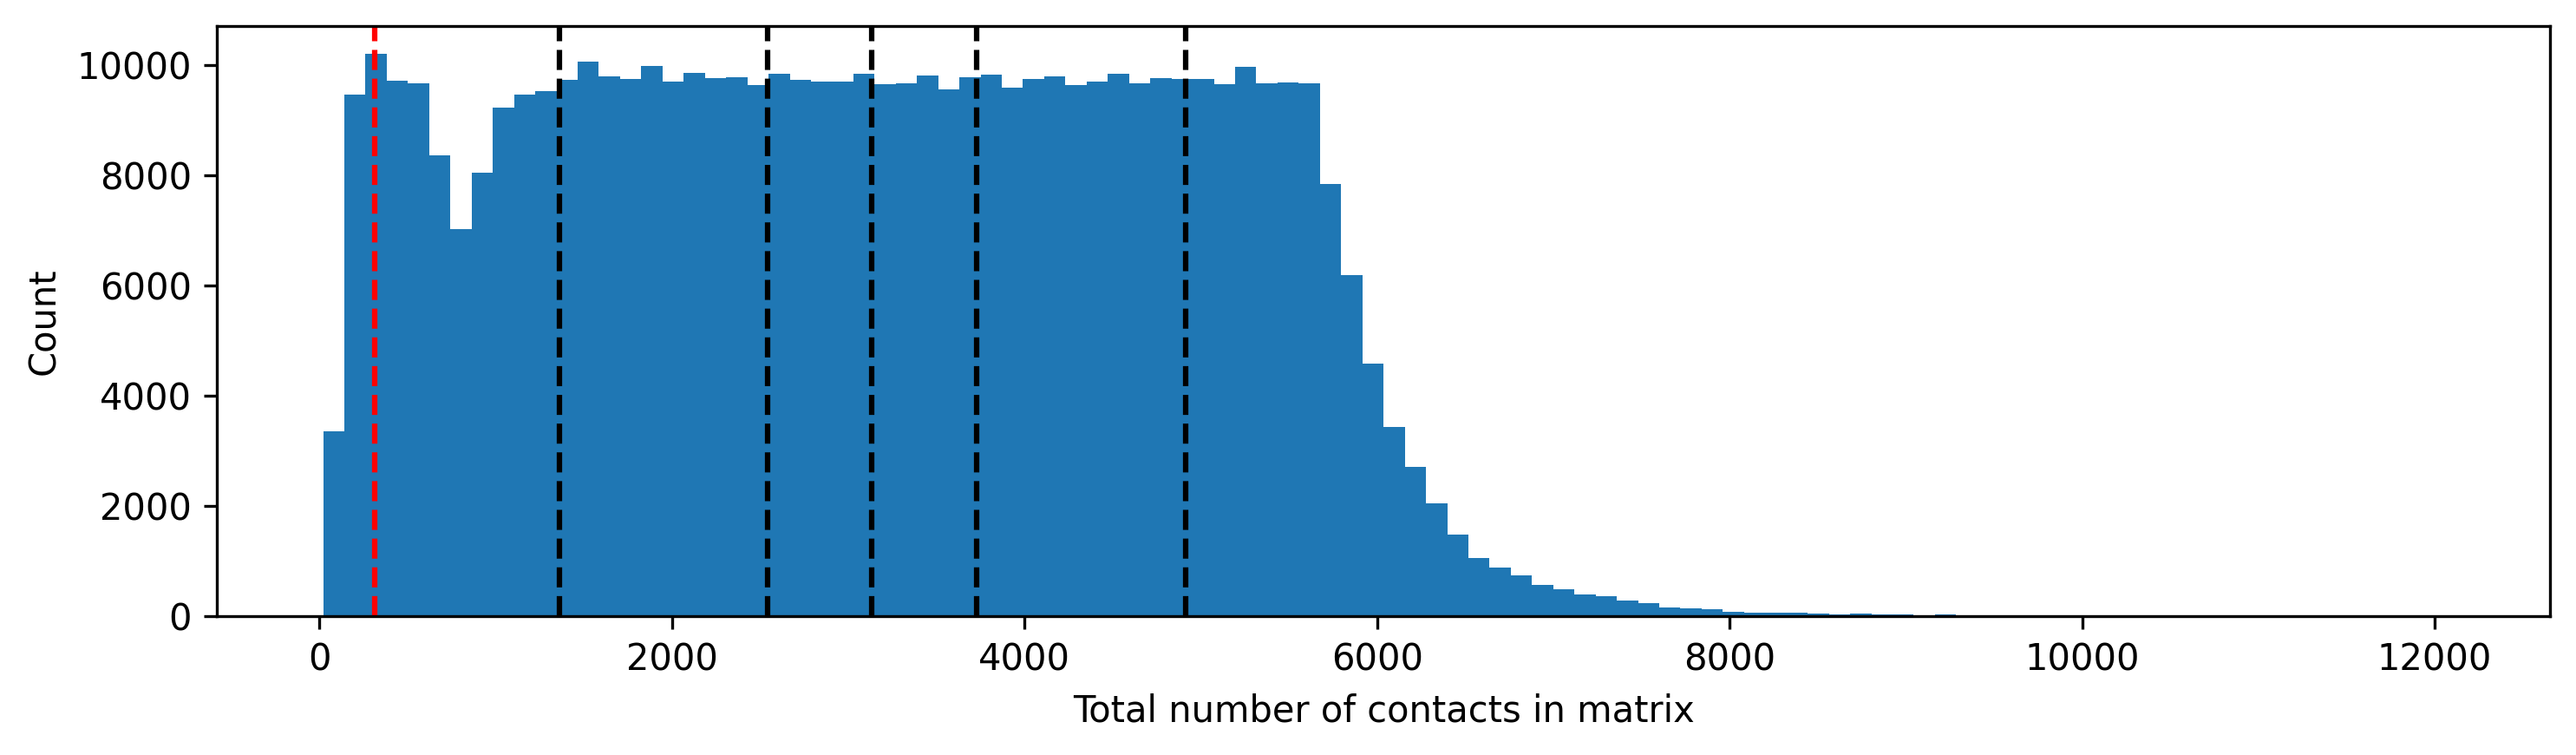

In [21]:
inter.dist()

In [22]:
inter.summary()

'CHM13v2.JHE' dataset summary - BS:5000 IS:10
	Whole dataset :
		x - (479576, 20, 20)
		y - (479576,)
		names - (479576,)
		groups - (479576,)
		0.0% of the samples are True


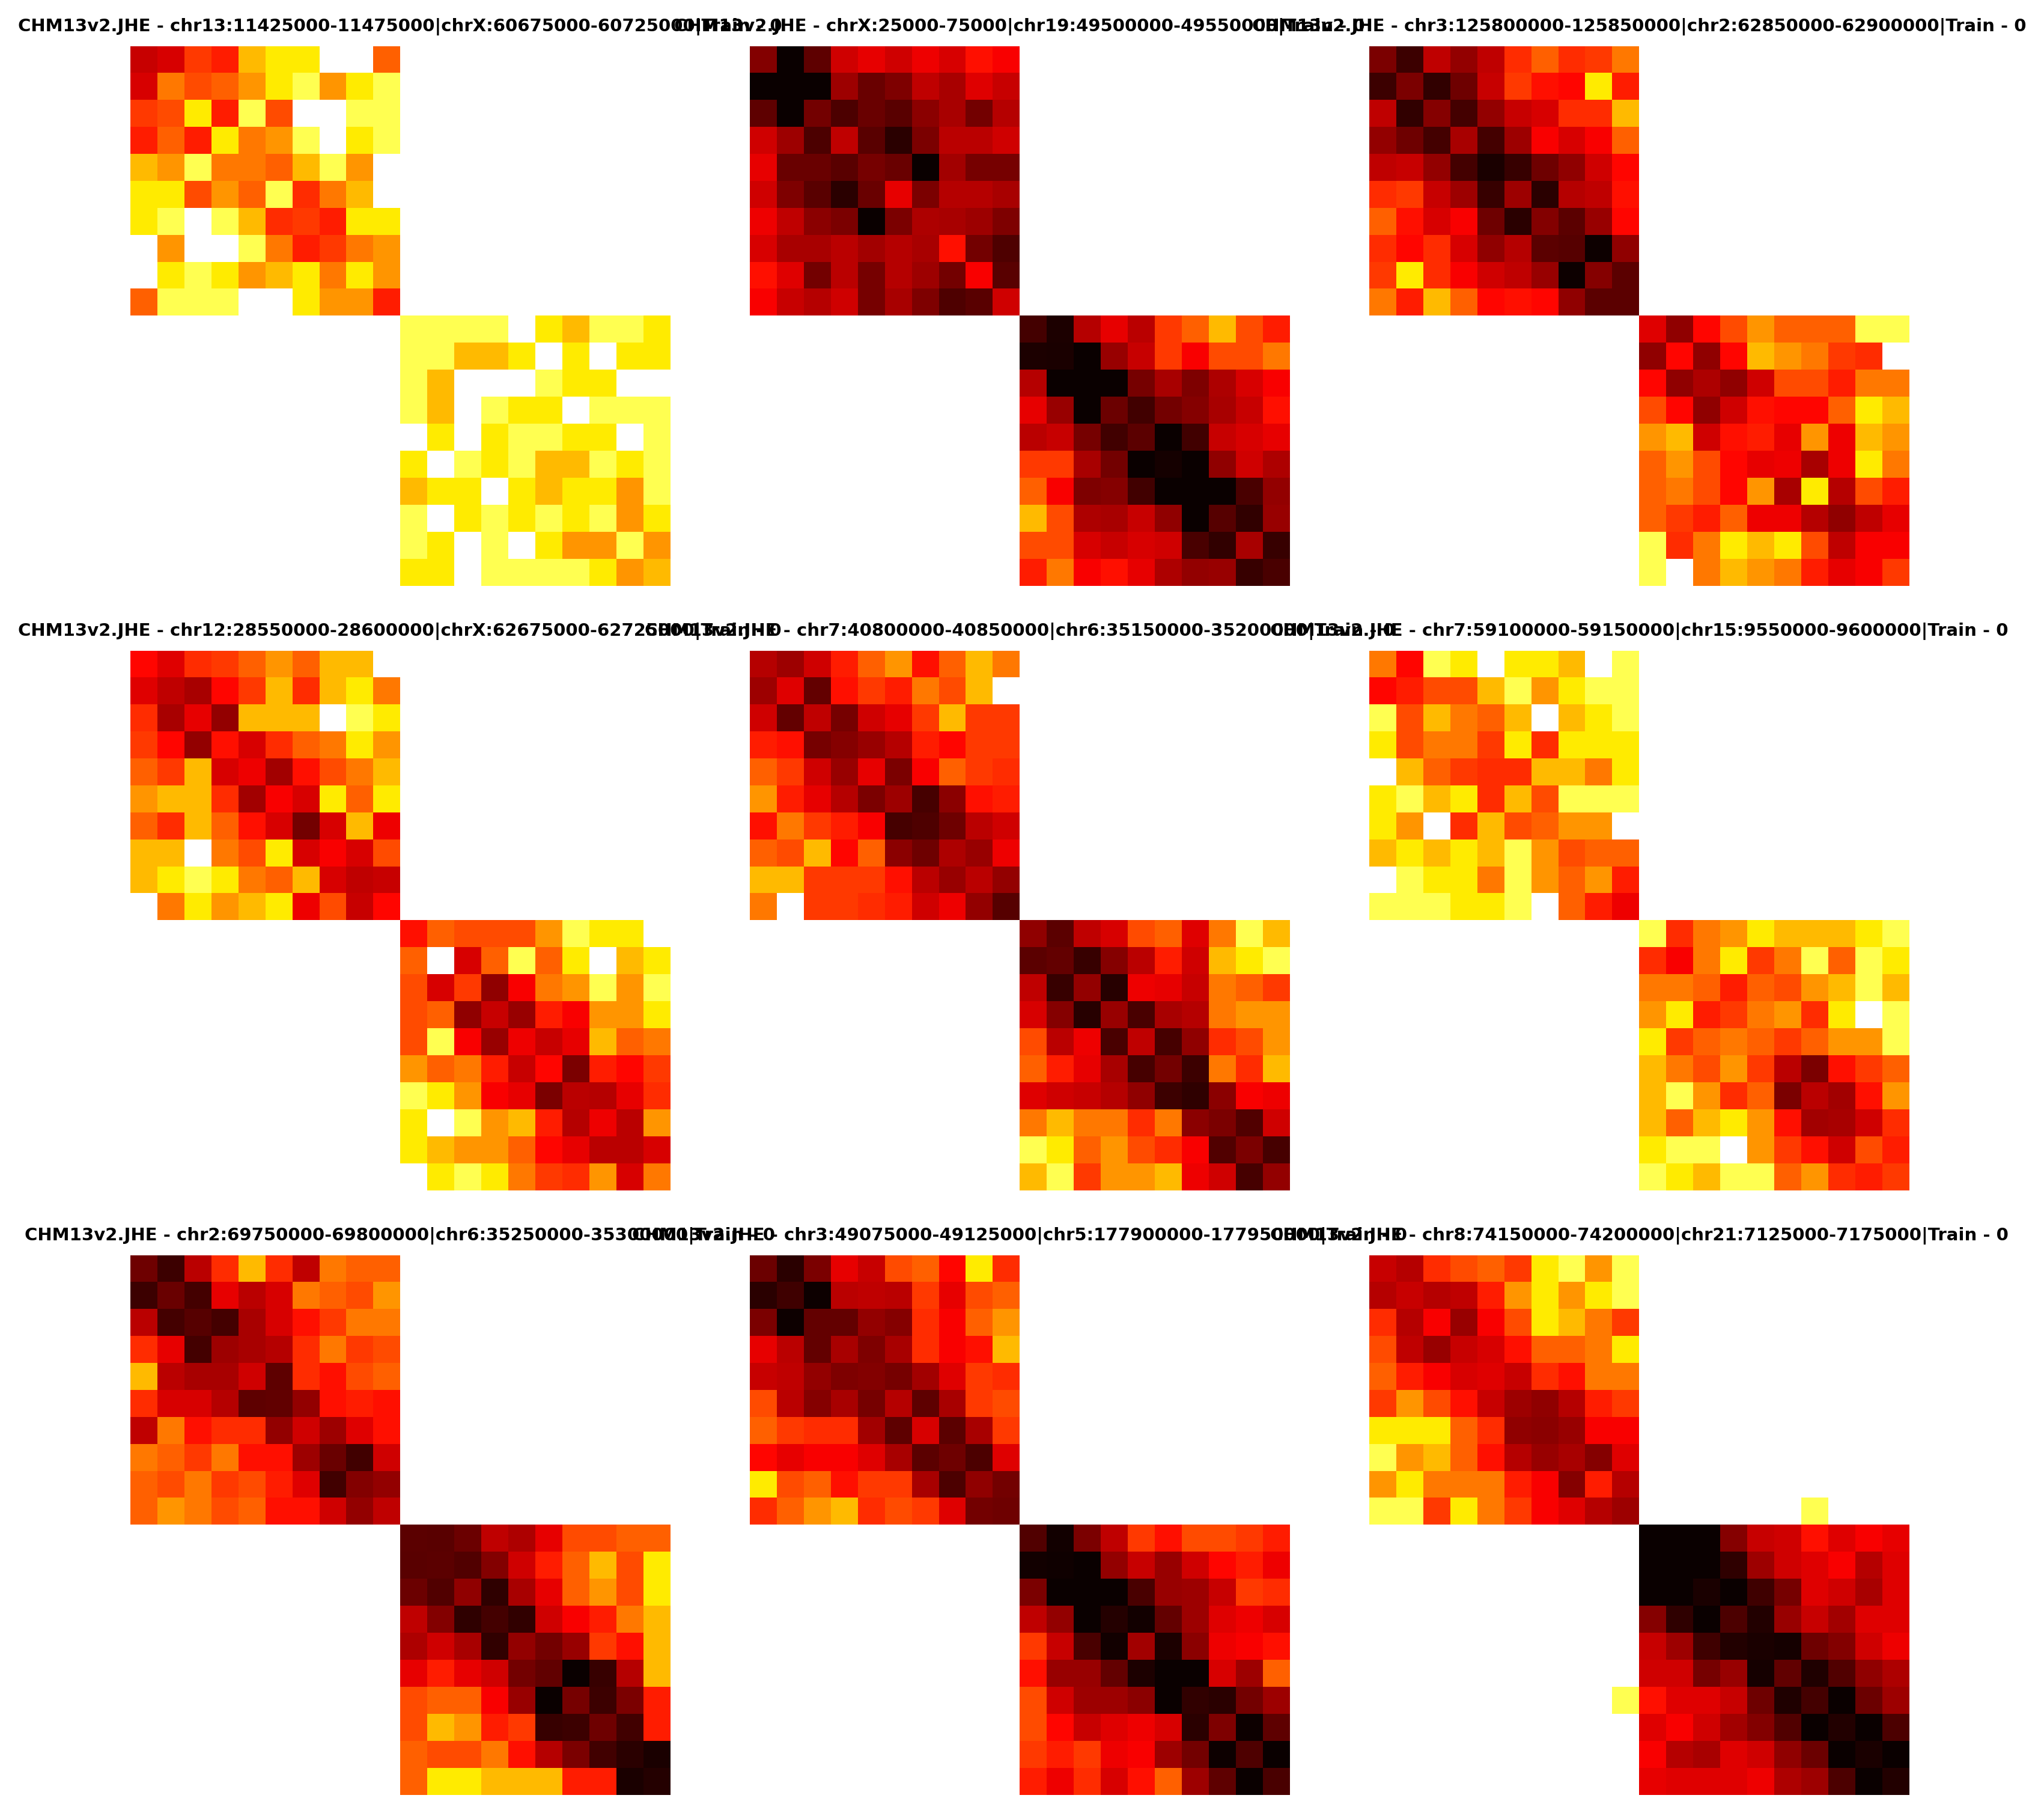

In [23]:
inter.show()

In [24]:
inter.save(savedir="/home/amergez/SPA-C/datasets/CHM13v2/SPA-C_ds/CHM13v2.InterFM.5K10S_Q0.EQ.hdf5")

	Writing dataset to /home/amergez/SPA-C/datasets/CHM13v2/SPA-C_ds/CHM13v2.InterFM.5K10S_Q0.EQ.hdf5
	Adding BS=5000 to IS=10 group
	Adding x to 10:5000 group
	Adding y to 10:5000 group
	Adding names to 10:5000 group
	Adding groups to 10:5000 group
Done !


## Intra matrices

```shell
$apps/HiC.sif python -u ${SPA_dir}/py_scripts/Cool2IntraM_FullMat.py \
  --cool ${dir}/aligned/${dir}.JHE.mcool \
  --image-size 10 \
  --bin-size 5000 \
  --splits ${dir}/references/SPLITS.txt \
  --output ${dir}/SPA-C_ds/${dir}.IntraFM.5K10S_Q0.hdf5
```

In [5]:
intra = dataset("/home/amergez/SPA-C/datasets/CHM13v2/SPA-C_ds/CHM13v2.IntraFM.5K10S_Q0.hdf5")
intra.summary()

SPA-C dataset v5.8.1

Loading /home/amergez/SPA-C/datasets/CHM13v2/SPA-C_ds/CHM13v2.IntraFM.5K10S_Q0.hdf5 ...
Done ! (6.692s)
Checking if labels are identical within each groups ...
Pass !

Dataset metadata :
	Cool2IntraM_FullMat.creation_date: 09/11/2026-15:26:51
	Cool2IntraM_FullMat.filter: None
	Cool2IntraM_FullMat.version: 1.9.1a
	data.type: Intra.FullMat
	dataset: CHM13v2.JHE

'CHM13v2.JHE' dataset summary - BS:5000 IS:10
	Whole dataset :
		x - (1221030, 20, 20)
		y - (1221030,)
		names - (1221030,)
		groups - (1221030,)
		100.0% of the samples are True


In [30]:
intra.N

array(['chr1_10_C2|Test', 'chr1_10_C3|Test', 'chr1_11_C2|Test', ...,
       'chrX_30840_C3|Train', 'chrX_30841_C2|Train',
       'chrX_30841_C3|Train'], dtype='<U20')

In [31]:
# Checking that chromosomes in each subset are the same as in the split file
chr_per_subset = {"Test":[], "Train":[], "Val":[]}
grp_per_subset = {"Test":[], "Train":[], "Val":[]}
for i, name in enumerate(intra.N):
    try:
        info1, info2, subset = name.split("|")
        ctg1, _ = info1.split(":")
        ctg2, _ = info2.split(":")
        chr_per_subset[subset].extend([ctg1, ctg2])
    except:
        info1, subset = name.split("|")
        ctg1 = info1.split("_")[0]
        chr_per_subset[subset].append(ctg1)
    
    grp_per_subset[subset].append(intra.G[i])

for key in chr_per_subset.keys():
    chr_per_subset[key] = set(chr_per_subset[key])
    grp_per_subset[key] = set(grp_per_subset[key])

print(chr_per_subset)
print(grp_per_subset)

{'Test': {'chr16', 'chr1'}, 'Train': {'chr12', 'chr20', 'chr4', 'chr21', 'chr3', 'chr11', 'chr14', 'chr2', 'chr13', 'chr17', 'chr15', 'chr8', 'chr22', 'chrX', 'chr6', 'chr5', 'chr7', 'chr19'}, 'Val': {'chr10', 'chr9', 'chr18'}}
{'Test': {np.uint16(2)}, 'Train': {np.uint16(0)}, 'Val': {np.uint16(1)}}


## Merging subsets

```shell
DS="CHM13v2"

apptainer exec --cleanenv $apps/SPA-C.sif python ${SPA_dir}/model_training/Multi2One.py \
    --dataset ${DS}/SPA-C_ds/${DS}.IntraFM.5K10S_Q0.hdf5 \
    CHM13.DS/${DS}.C4A.IntraFM.5K10S_Q0.hdf5 \
    CHM13.DS/${DS}.C4B.IntraFM.5K10S_Q0.hdf5 \
    CHM13.DS/${DS}.C4C.IntraFM.5K10S_Q0.hdf5 \
    ${DS}/SPA-C_ds/${DS}.InterFM.5K10S_Q0.EQ.hdf5 \
    --output CHM13.DS/${DS}.DS_5K10S_Q0.C4X.hdf5 \
    --name ${DS}.DS_5K10S_Q0.C4X.raw
```

In [27]:
ds = dataset("/home/amergez/SPA-C/datasets/CHM13.DS/CHM13v2.DS_5K10S_Q0.C4X.hdf5", skip_check=True)
ds.summary()

SPA-C dataset v5.8.1

Loading /home/amergez/SPA-C/datasets/CHM13.DS/CHM13v2.DS_5K10S_Q0.C4X.hdf5 ...
Done ! (11.836s)

Dataset metadata :
	CHM13v2.C4A.JHE|Cool2IntraM_FullMat.creation_date: 10/11/2026-11:52:20
	CHM13v2.C4A.JHE|Cool2IntraM_FullMat.filter: None
	CHM13v2.C4A.JHE|Cool2IntraM_FullMat.version: 1.9.1d
	CHM13v2.C4A.JHE|data.type: Intra.FullMat
	CHM13v2.C4A.JHE|dataset: CHM13v2.C4A.JHE
	CHM13v2.C4B.JHE|Cool2IntraM_FullMat.creation_date: 10/11/2026-11:58:12
	CHM13v2.C4B.JHE|Cool2IntraM_FullMat.filter: None
	CHM13v2.C4B.JHE|Cool2IntraM_FullMat.version: 1.9.1d
	CHM13v2.C4B.JHE|data.type: Intra.FullMat
	CHM13v2.C4B.JHE|dataset: CHM13v2.C4B.JHE
	CHM13v2.C4C.JHE|Cool2IntraM_FullMat.creation_date: 10/11/2026-12:03:00
	CHM13v2.C4C.JHE|Cool2IntraM_FullMat.filter: None
	CHM13v2.C4C.JHE|Cool2IntraM_FullMat.version: 1.9.1d
	CHM13v2.C4C.JHE|data.type: Intra.FullMat
	CHM13v2.C4C.JHE|dataset: CHM13v2.C4C.JHE
	CHM13v2.JHE|Cool2InterM_FullMat.creation_date: 09/11/2026-15:43:59
	CHM13v2.JHE|Cool

In [32]:
# Checking that chromosomes in each subset are the same as in the split file
chr_per_subset = {"Test":[], "Train":[], "Val":[]}
grp_per_subset = {"Test":[], "Train":[], "Val":[]}
for i, name in enumerate(ds.N):
    try:
        info1, info2, subset = name.split("|")
        ctg1, _ = info1.split(":")
        ctg2, _ = info2.split(":")
        chr_per_subset[subset].extend([ctg1, ctg2])
    except:
        info1, subset = name.split("|")
        ctg1 = info1.split("_")[0]
        chr_per_subset[subset].append(ctg1)
    
    grp_per_subset[subset].append(ds.G[i])

for key in chr_per_subset.keys():
    chr_per_subset[key] = set(chr_per_subset[key])
    grp_per_subset[key] = set(grp_per_subset[key])

print(chr_per_subset)
print(grp_per_subset)

{'Test': {'chr16', 'chr1'}, 'Train': {'chr12', 'chr20', 'chr4', 'chr21', 'chr3', 'chr11', 'chr14', 'chr2', 'chr13', 'chr17', 'chr15', 'chr8', 'chr22', 'chrX', 'chr6', 'chr5', 'chr7', 'chr19'}, 'Val': {'chr10', 'chr9', 'chr18'}}
{'Test': {np.uint16(2)}, 'Train': {np.uint16(0)}, 'Val': {np.uint16(1)}}


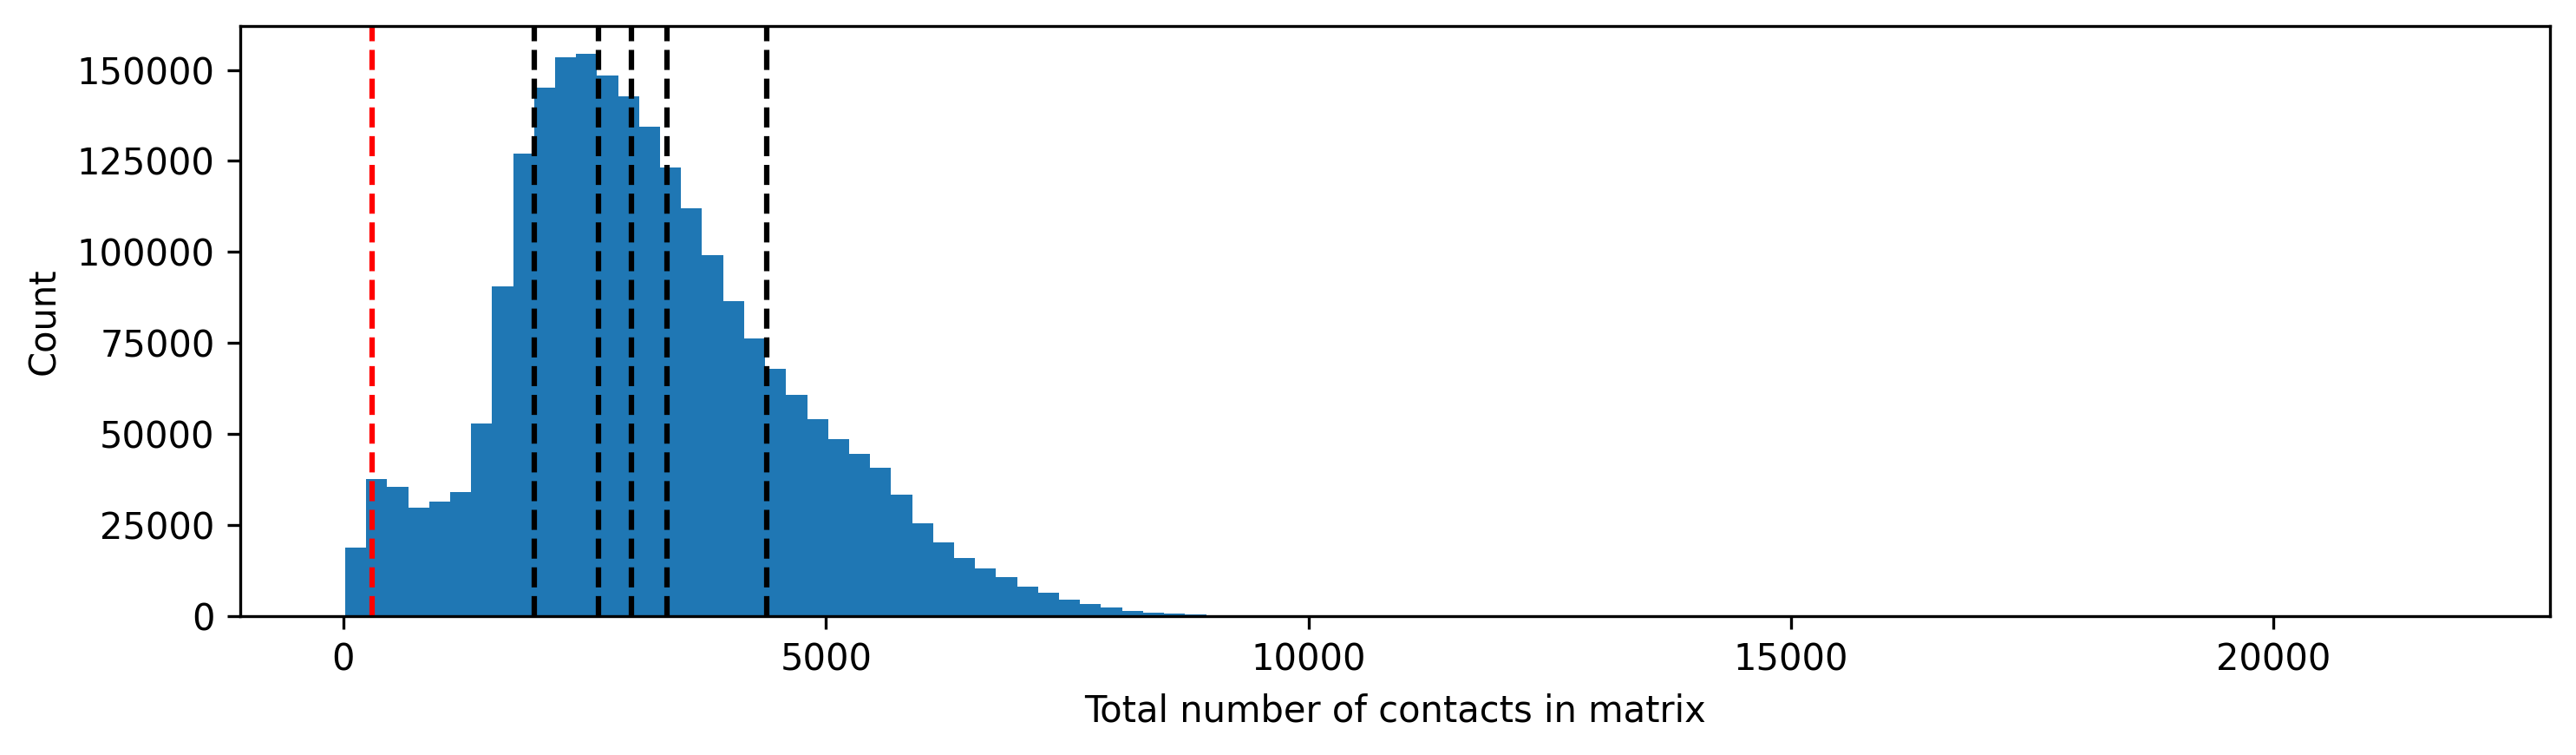

In [33]:
ds.dist()

## Generating dataset to set the threshold

```shell
BASE_DIR="/home/amergez/SPA-C/datasets"

for dir in CHM13v2.C4A CHM13v2.C4B CHM13v2.C4C; do
  # Creating the dataset
  $apps/HiC.sif python -u ${SPA_dir}/py_scripts/Cool2IntraM_FullMat.py \
    --cool ${BASE_DIR}/${dir}.JHE.mcool \
    --image-size 10 \
    --bin-size 5000 \
    --breakpoint ${BASE_DIR}/raw_data/CHM13.Chimera/${dir}.bkp \
    --output ${BASE_DIR}/CHM13.DS/${dir}.THRES.5K10S_Q0.hdf5 \
    --name-table ${BASE_DIR}/raw_data/CHM13.Chimera/${dir}.conversion_table.txt \
    --splits ${BASE_DIR}/raw_data/CHM13v2/SPLITS.txt \
    --padding "-1"
done
```

```shell
DS="CHM13v2"

apptainer exec --cleanenv $apps/SPA-C.sif python ${SPA_dir}/model_training/Multi2One.py \
    --dataset ${DS}/SPA-C_ds/${DS}.IntraFM.5K10S_Q0.hdf5 \
    CHM13.DS/${DS}.C4A.THRES.5K10S_Q0.hdf5 \
    CHM13.DS/${DS}.C4B.THRES.5K10S_Q0.hdf5 \
    CHM13.DS/${DS}.C4C.THRES.5K10S_Q0.hdf5 \
    --output CHM13.DS/${DS}.DS_5K10S_Q0.C4X_THRES.hdf5 \
    --name ${DS}.DS_5K10S_Q0.C4X_THRES.raw
```

# HG002

## Generating chimeras

We used ChimericContigs.py v1.6.2.

```shell
apps="apptainer" # Path to apptainer images folder
SPA_dir="SPA-C" # Directory of the Git repo
BASE_DIR="datasets"
DS="HG002.H1"
dir="${BASE_DIR}/${DS}" # Directory of HG002.H1 dataset

# Inter only
$apps/HiC.sif python -u ${SPA_dir}/model_training/ChimericContigs.py \
  --fasta ${dir}/${DS}.fa \
  --out ${BASE_DIR}/HG002.Chimera/${DS}.C4A.fa \
  --seed 42 \
  --paf ${BASE_DIR}/HG002.Chimera/${DS}.C4A.paf \
  --repetition 2000 \
  --size 200000 \
  --simple-names "C4A"

# Intra only
$apps/HiC.sif python -u ${SPA_dir}/model_training/ChimericContigs.py \
  --fasta ${dir}/${DS}.fa \
  --out ${BASE_DIR}/HG002.Chimera/${DS}.C4B.fa \
  --seed 42 \
  --paf ${BASE_DIR}/HG002.Chimera/${DS}.C4B.paf \
  --repetition 2500 \
  --size 200000 \
  --intra \
  --simple-names "C4B"

# Inversions only
$apps/HiC.sif python -u ${SPA_dir}/model_training/ChimericContigs.py \
  --fasta ${dir}/${DS}.fa \
  --out ${BASE_DIR}/HG002.Chimera/${DS}.C4C.fa \
  --seed 42 \
  --paf ${BASE_DIR}/HG002.Chimera/${DS}.C4C.paf \
  --repetition 2500 \
  --size 200000 \
  --inversion \
  --simple-names "C4C"
```

```shell
BASE_DIR="/home/amergez/SPA-C/datasets"

for dir in CHM13v2.C4A CHM13v2.C4B CHM13v2.C4C; do
  # Creating the dataset
  $apps/HiC.sif python -u ${SPA_dir}/py_scripts/Cool2IntraM_FullMat.py \
    --cool ${BASE_DIR}/${dir}.JHE.mcool \
    --image-size 10 \
    --bin-size 5000 \
    --breakpoint ${BASE_DIR}/raw_data/CHM13.Chimera/${dir}.bkp \
    --only-negatives \
    --output ${BASE_DIR}/CHM13.DS/${dir}.IntraFM.5K10S_Q0.hdf5 \
    --name-table ${BASE_DIR}/raw_data/CHM13.Chimera/${dir}.conversion_table.txt \
    --splits ${BASE_DIR}/raw_data/CHM13v2/SPLITS.txt \
    --padding "-1"
done
```

## Inter matrices

```shell
$apps/HiC.sif python -u ${SPA_dir}/py_scripts/Cool2InterM_FullMat.py \
  --cool ${dir}/aligned/${dir}.JHE.mcool \
  --image-size 10 \
  --bin-size 5000 \
  --steps 5 \
  --threads 8 \
  --output ${dir}/SPA-C_ds/${dir}.InterFM.5K10S_Q0.hdf5 \
  --chrom-sizes ${dir}/references/${dir}.fa.chrom.sizes \
  --splits ${dir}/references/SPLITS.txt \
  --tmp-dir ${dir}/SPA-C_ds/tmp
```